In [1]:
from google.colab import drive
drive.mount('/content/drive')
#

Mounted at /content/drive


🖼️ الصورة المطلوبة:


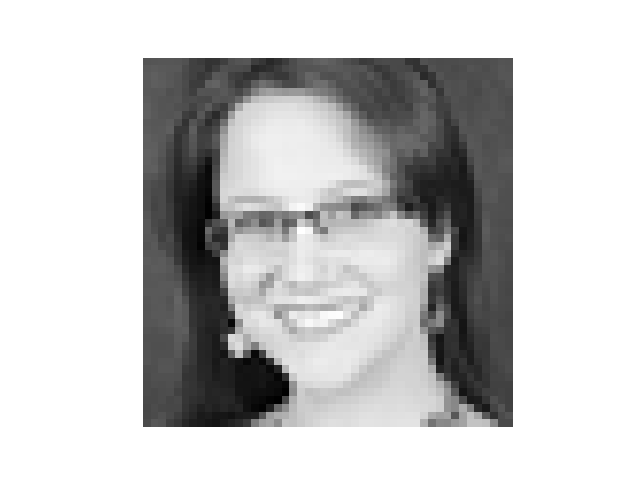

In [8]:
from transformers import AutoImageProcessor, AutoModelForImageClassification
from IPython.display import display, Image as IPImage
from PIL import Image
import torch
import numpy as np

# 1. تحديد مسار النموذج والصورة
model_dir = (
    "/content/drive/MyDrive/TransformersCode/customer_serves/vit_emotion_model"
)
image_path = (
    "/content/drive/MyDrive/TransformersCode/customer_serves/photos/Happiness7.png"
)

# 2. عرض الصورة أولاً في كولاب للتأكد منها مرئياً
print("🖼️ الصورة المطلوبة:")
display(IPImage(filename=image_path, width=224, height=224))






In [13]:

processor = AutoImageProcessor.from_pretrained(model_dir)
model = AutoModelForImageClassification.from_pretrained(model_dir)
model.eval()


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ViTLayer(
        (attention): ViTAttention(
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (o_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layernorm_before): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (layernorm_after): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (mlp): ViTMLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Linear(in_features=3072, out

In [11]:
# 4. فتح الصورة ومعالجتها للتنبؤ
image = Image.open(image_path).convert("RGB")
inputs = processor(images=image, return_tensors="pt")

In [12]:
# 5. قاموس تعريف المشاعر السبعة
emotion_mapping = {
    0: "Angry (غاضب)",
    1: "Disgust (مشمئز)",
    2: "Fear (خائف)",
    3: "Happy (سعيد)",
    4: "Sad (حزين)",
    5: "Surprise (متفاجئ)",
    6: "Neutral (طبيعي/حيادي)"
}

# التنبؤ بالنتيجة
with torch.no_grad():
  outputs = model(**inputs)
  logits = outputs.logits

predicted_class_idx = logits.argmax(-1).item()

# طباعة النتيجة النهائية باستخدام أسماء المشاعر
if predicted_class_idx in emotion_mapping:
  predicted_emotion = emotion_mapping[predicted_class_idx]
  print(f"\n✨ الشعور المتوقع: {predicted_emotion} (الفئة رقم {predicted_class_idx})")
else:
  print(f"\n✨ الفئة المتوقعة برقم: {predicted_class_idx}")

# طباعة الاحتمالات لكل المشاعر بالتفصيل
probabilities = torch.nn.functional.softmax(logits, dim=-1)[0]
print("\n📊 نسب احتمالية المشاعر:")
for idx, prob in enumerate(probabilities):
  emotion_name = emotion_mapping.get(idx, f"فئة غير معروفة {idx}")
  print(f"  - {emotion_name}: {prob.item() * 100:.2f}%")


✨ الشعور المتوقع: Happy (سعيد) (الفئة رقم 3)

📊 نسب احتمالية المشاعر:
  - Angry (غاضب): 1.57%
  - Disgust (مشمئز): 2.12%
  - Fear (خائف): 0.88%
  - Happy (سعيد): 84.63%
  - Sad (حزين): 1.73%
  - Surprise (متفاجئ): 2.79%
  - Neutral (طبيعي/حيادي): 6.28%
